Exploratory Data Analysis

Roles to explore:

In [4]:
# importing Librarires
import ast
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from datasets import load_dataset


#loading Data
dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

# Data cleanup
df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else x)

In [5]:
df_DA_US = df[(df['job_country'] == 'United States') & (df['job_title_short'] == 'Data Analyst')]

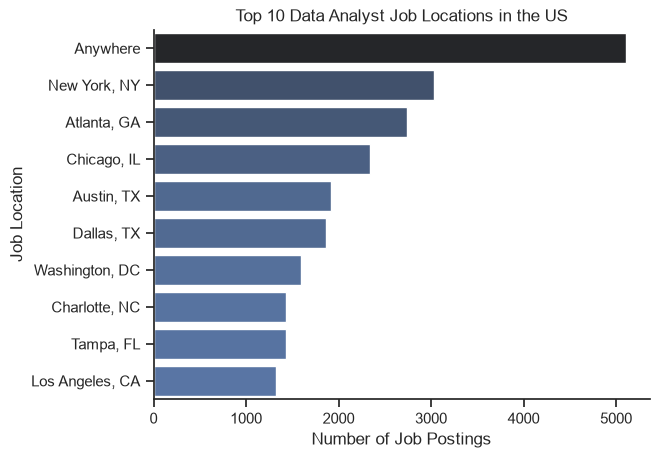

In [12]:
# Get the 10 most common job locations
df_plot = df_DA_US['job_location'].value_counts().head(10).to_frame()


# Reset the index and rename columns
df_plot = df_plot.reset_index()
df_plot.columns = ['job_location', 'count']

# Create bar plot
sns.set_theme(style= 'ticks')
sns.barplot(data=df_plot, x='count', y='job_location', hue= 'count', palette='dark:b_r', legend=False)
sns.despine()
plt.title('Top 10 Data Analyst Job Locations in the US')
plt.xlabel('Number of Job Postings')
plt.ylabel('Job Location')

plt.show()

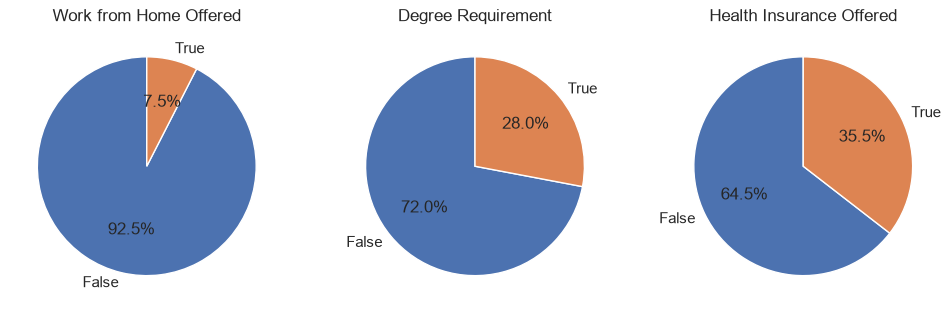

In [18]:
dict_column = {
    'job_work_from_home':'Work from Home Offered',
    'job_no_degree_mention': 'Degree Requirement',
    'job_health_insurance':'Health Insurance Offered'
}

fig, ax = plt.subplots(1, 3)
fig.set_size_inches(12, 5)

for i, (column, title) in enumerate(dict_column.items()):
    ax[i].pie(df_DA_US[column].value_counts(), labels= ['False', 'True'], autopct= '%1.1f%%', startangle= 90)
    ax[i].set_title(title)

plt.show()

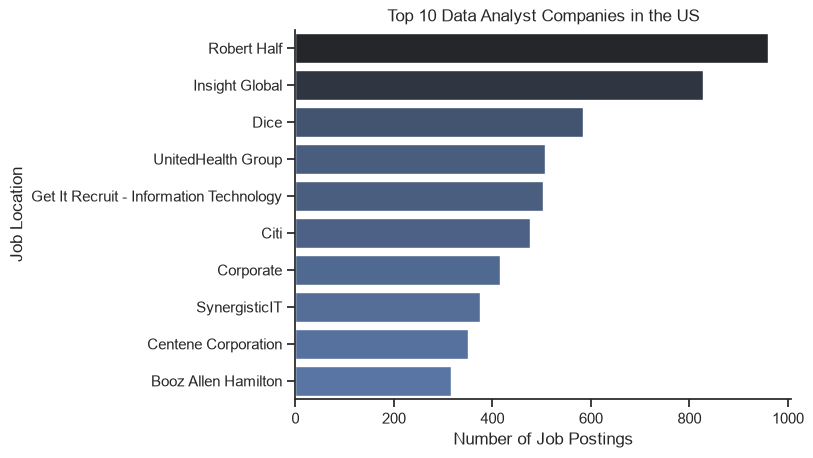

In [20]:
# Get the 10 most common company name
df_plot = df_DA_US['company_name'].value_counts().head(10).to_frame()


# Reset the index and rename columns
df_plot = df_plot.reset_index()
df_plot.columns = ['company_name', 'count']

# Create bar plot
sns.set_theme(style= 'ticks')
sns.barplot(data=df_plot, x='count', y='company_name', hue= 'count', palette='dark:b_r', legend=False)
sns.despine()
plt.title('Top 10 Data Analyst Companies in the US')
plt.xlabel('Number of Job Postings')
plt.ylabel('Job Location')

plt.show()